# 02 — Modélisation et évaluation des disponibilités Vélib’
### Prévision à 30 minutes — Ridge et CatBoost

**Objectif :** prédire le nombre de vélos disponibles dans une station à l’horizon de 30 minutes.

## 0. Environnement

Dépendances : `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `catboost` et `scipy`. 


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay)
from catboost import CatBoostRegressor

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 35)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True})
print("Bibliothèques chargées.")

Bibliothèques chargées.


## 1. Configuration expérimentale

Paramètres du découpage chronologique, des expériences et des modèles

In [2]:
CSV_PATH = Path("raw/data/historique_nettoye.csv")

N_TEST_DAYS = 4
N_VALID_DAYS = 4
HORIZON_MIN = 30
RAYON_VOISINAGE_M = 500

EXPERIENCES_COMPLEMENTAIRES = True
RUN_WALK_FORWARD = False
RUN_FINAL_TEST = False

MAX_TRAIN_ROWS = None
MAX_VALID_ROWS = None
CATBOOST_ITERATIONS = 300
CATBOOST_DEPTH = 6
CATBOOST_THREADS = 4
RIDGE_ALPHAS = (1.0, 10.0, 100.0)
print("Fichier d'entrée :", CSV_PATH)


Fichier d'entrée : raw/data/historique_nettoye.csv


## 2. Chargement du jeu de données


In [3]:
if not CSV_PATH.exists():
    raise FileNotFoundError(f"CSV introuvable : {CSV_PATH.resolve()}")

df = pd.read_csv(CSV_PATH, dtype={"station_code": "string"}, low_memory=False)
colonnes_requises = {
    "horodatage", "station_code", "available", "available_t30", "capacity",
    "available_last_30", "delta_t30", "heure_sin", "heure_cos",
    "heure", "is_weekend", "latitude", "longitude",
}
manquantes = colonnes_requises - set(df.columns)
if manquantes:
    raise ValueError(f"Colonnes absentes de l'export 01-exploration : {sorted(manquantes)}")

# Conversion de lecture nécessaire aux découpages temporels.
df["horodatage"] = pd.to_datetime(df["horodatage"], utc=True, errors="raise")
colonnes_non_nulles = ["horodatage", "station_code", "available", "available_t30",
                       "capacity", "available_last_30", "delta_t30", "latitude", "longitude"]
if df[colonnes_non_nulles].isna().any().any():
    raise ValueError("Valeurs manquantes dans les colonnes obligatoires de l'export.")
if df.duplicated(["station_code", "horodatage"]).any():
    raise ValueError("Doublons station/horodatage dans l'export 01-exploration.")
if (df["capacity"] <= 0).any() or (df[["available", "available_t30"]] < 0).any().any():
    raise ValueError("Valeurs incohérentes dans l'export 01-exploration.")

df = df.sort_values(["horodatage", "station_code"]).reset_index(drop=True)
print(f"Observations : {len(df):,} | Stations : {df['station_code'].nunique():,}")
print(f"Période : {df['horodatage'].min()} — {df['horodatage'].max()}")

Observations : 6,481,764 | Stations : 1,217
Période : 2026-10-16 13:50:00+00:00 — 2026-11-06 21:00:00+00:00


## 3. Variables historiques

Création des disponibilités observées 15 et 30 minutes avant l'instant de prédiction, puis de leur évolution à 15 minutes. Les jointures reposent sur des horodatages exacts par station. 

In [4]:
HISTORIQUE = ["available_last_30", "delta_t30"]
print("Historique réutilisé depuis 01-exploration :", HISTORIQUE)
print("Disponibilité passée renseignée :", f"{df['available_last_30'].notna().mean():.1%}")

Historique réutilisé depuis 01-exploration : ['available_last_30', 'delta_t30']
Disponibilité passée renseignée : 100.0%


## 4. Variables de voisinage


In [5]:
from sklearn.neighbors import BallTree
from scipy import sparse

COLS_VOISINAGE = ["nb_voisins_500m", "voisins_dispo_moyenne", "voisins_observes"]

# Coordonnées par station : même logique géographique que 01-exploration.
stations_geo = df.groupby("station_code", sort=True)[["latitude", "longitude"]].first()
coord_rad = np.radians(stations_geo[["latitude", "longitude"]].to_numpy(dtype=float))
rayon_radians = RAYON_VOISINAGE_M / 6_371_000
voisines_idx = BallTree(coord_rad, metric="haversine").query_radius(coord_rad, r=rayon_radians)

# Matrice station x station : 1 si la colonne est voisine de la ligne.
source, cible = [], []
for i, indices in enumerate(voisines_idx):
    autres = indices[indices != i]  # exclure la station elle-même
    source.extend([i] * len(autres))
    cible.extend(autres.tolist())
n_stations = len(stations_geo)
adjacence = sparse.csr_matrix(
    (np.ones(len(source), dtype=np.float32), (source, cible)),
    shape=(n_stations, n_stations),
)

# Matrices horodatage x station : valeurs observées uniquement à l'instant t.
station_i = stations_geo.index.get_indexer(df["station_code"])
temps_i, horodatages = pd.factorize(df["horodatage"], sort=True)
n_temps = len(horodatages)
forme = (n_temps, n_stations)
valeurs = df["available"].to_numpy(dtype=np.float32)
stocks = sparse.csr_matrix((valeurs, (temps_i, station_i)), shape=forme)
presences = sparse.csr_matrix(
    (np.ones(len(df), dtype=np.float32), (temps_i, station_i)), shape=forme
)

# Sommes et nombre d'observations des stations voisines au même instant.
sommes_voisines = (stocks @ adjacence.T).toarray()
comptes_voisines = (presences @ adjacence.T).toarray()
sommes_ligne = sommes_voisines[temps_i, station_i]
comptes_ligne = comptes_voisines[temps_i, station_i]

df["nb_voisins_500m"] = np.asarray(adjacence.sum(axis=1)).ravel().astype(int)[station_i]
df["voisins_observes"] = comptes_ligne.astype(int)
df["voisins_dispo_moyenne"] = np.divide(
    sommes_ligne, comptes_ligne,
    out=np.full(len(df), np.nan, dtype=np.float32),
    where=comptes_ligne > 0,
)

del sommes_voisines, comptes_voisines, stocks, presences, sommes_ligne, comptes_ligne
print("Variables de voisinage calculées :", COLS_VOISINAGE)
print("Stations sans voisine dans un rayon de 500 m :", int((np.asarray(adjacence.sum(axis=1)).ravel() == 0).sum()))

Variables de voisinage calculées : ['nb_voisins_500m', 'voisins_dispo_moyenne', 'voisins_observes']
Stations sans voisine dans un rayon de 500 m : 36


## 5. Variables temporelles et météorologiques


In [6]:
# Date locale utilisée pour le découpage, pas comme variable prédictive.
df["date_paris"] = df["horodatage"].dt.tz_convert("Europe/Paris").dt.strftime("%Y-%m-%d")

METEO_POSSIBLE = ["temperature_2m", "wind_speed_10m", "precipitation", "rain"]
METEO = [c for c in METEO_POSSIBLE if c in df.columns]
# La cible future ne doit jamais être fournie au modèle.
EXCLUES_POUR_FUITE = ["available_t30", "tendance", "delta_abs", "is_rush_hour"]
print("Variables météo disponibles :", METEO)
if not METEO:
    print("ATTENTION : aucune variable météo dans le CSV. "
          "Vérifier la fusion météo dans 01-exploration et réexporter le CSV. "
          "L’ablation météo ne sera pas exécutée.")

Variables météo disponibles : ['temperature_2m', 'wind_speed_10m', 'precipitation', 'rain']


## 6. Découpage chronologique

Séparation en ensembles d'entraînement, de validation et de test sur les dates locales de Paris

In [7]:
dates_uniques = pd.Index(sorted(df["date_paris"].unique()))
if len(dates_uniques) < N_TEST_DAYS + N_VALID_DAYS + 3:
    raise ValueError(
        f"Seulement {len(dates_uniques)} jours présents. "
        "Réduire N_TEST_DAYS / N_VALID_DAYS ou attendre davantage de données.")
DATE_TEST = dates_uniques[-N_TEST_DAYS]
DATE_VALID = dates_uniques[-(N_TEST_DAYS + N_VALID_DAYS)]
DEBUT_VALID = pd.Timestamp(DATE_VALID, tz="Europe/Paris").tz_convert("UTC")
DEBUT_TEST = pd.Timestamp(DATE_TEST, tz="Europe/Paris").tz_convert("UTC")
HORIZON = pd.Timedelta(minutes=HORIZON_MIN)

# Pour que la cible t+30 d'une période ne déborde pas sur la période suivante.
train_complet = df.loc[df["horodatage"] + HORIZON < DEBUT_VALID].copy()
valid_complet = df.loc[(df["horodatage"] >= DEBUT_VALID) &
                       (df["horodatage"] + HORIZON < DEBUT_TEST)].copy()
test_reserve = df.loc[df["horodatage"] >= DEBUT_TEST].copy()

def sous_echantillon(frame, maximum):
    if maximum is None or len(frame) <= maximum:
        return frame.reset_index(drop=True)
    return (frame.sample(n=maximum, random_state=SEED)
                 .sort_values("horodatage").reset_index(drop=True))

train = sous_echantillon(train_complet, MAX_TRAIN_ROWS)
valid = sous_echantillon(valid_complet, MAX_VALID_ROWS)
if train.empty or valid.empty or test_reserve.empty:
    raise ValueError("Train, validation ou test vide : vérifier les dates du CSV.")

bilan_split = pd.DataFrame([
    {"Partie": "Train", "Début": train["horodatage"].min(),
     "Fin": train["horodatage"].max(), "Lignes": len(train)},
    {"Partie": "Validation", "Début": valid["horodatage"].min(),
     "Fin": valid["horodatage"].max(), "Lignes": len(valid)},
    {"Partie": "Test réservé", "Début": test_reserve["horodatage"].min(),
     "Fin": test_reserve["horodatage"].max(), "Lignes": len(test_reserve)},
])
display(bilan_split)
print("Test final réservé à partir du", DATE_TEST, "(heure de Paris).")
print("Nombre de jours distincts : train", train["date_paris"].nunique(),
      "| validation", valid["date_paris"].nunique(),
      "| test", test_reserve["date_paris"].nunique())
if MAX_TRAIN_ROWS is not None or MAX_VALID_ROWS is not None:
    print("Attention : échantillonnage actif ; ne pas comparer directement à un entraînement complet.")

,Partie,Début,Fin,Lignes
0,Train,2026-10-16 13:50:00+00:00,2026-10-29 22:25:00+00:00,4220819
1,Validation,2026-10-29 23:00:00+00:00,2026-11-02 21:10:00+00:00,1290330
2,Test réservé,2026-11-03 00:05:00+00:00,2026-11-06 21:00:00+00:00,963325


Test final réservé à partir du 2026-11-03 (heure de Paris).
Nombre de jours distincts : train 14 | validation 4 | test 4


## 7. Familles de variables et expériences

Comparaison des configurations avec et sans voisinage. Les ablations retirent successivement la météo, l'historique ou les variables horaires. La configuration « Variables essentielles » utilise uniquement les variables de base.

In [8]:
BASE = ["available", "capacity", "velo_meca", "velo_elec",
        "latitude", "longitude", "heure_sin", "heure_cos",
        "heure", "is_weekend"]
VOISINAGE = COLS_VOISINAGE
# Seules les colonnes effectivement exportées par 01 sont utilisées.
BASE = [c for c in BASE if c in df.columns]

EXPERIENCES = {
    "Sans voisinage": BASE + HISTORIQUE + METEO,
    "Avec voisinage": BASE + HISTORIQUE + METEO + VOISINAGE,
}
if EXPERIENCES_COMPLEMENTAIRES:
    EXPERIENCES.update({
        "Variables essentielles": BASE,
        "Sans historique": BASE + METEO + VOISINAGE,
        "Sans horaire": [c for c in BASE if c not in
                         {"heure_sin", "heure_cos", "heure", "is_weekend"}]
                         + HISTORIQUE + METEO + VOISINAGE,
    })
    if METEO:
        EXPERIENCES["Sans météo"] = BASE + HISTORIQUE + VOISINAGE
EXPERIENCES = {k: list(dict.fromkeys(v)) for k, v in EXPERIENCES.items()}
for nom, features in EXPERIENCES.items():
    interdites = set(features) & set(EXCLUES_POUR_FUITE)
    assert not interdites, (nom, interdites)
    print(f"{nom:23s} : {len(features)} numériques + station_code")

Sans voisinage          : 16 numériques + station_code
Avec voisinage          : 19 numériques + station_code
Variables essentielles  : 10 numériques + station_code
Sans historique         : 17 numériques + station_code
Sans horaire            : 15 numériques + station_code
Sans météo              : 15 numériques + station_code


## 8. Métriques d'évaluation

- **MAE** : erreur absolue moyenne en nombre de vélos.
- **RMSE** : racine de l'erreur quadratique moyenne, sensible aux erreurs importantes.
- **R²** : coefficient de détermination.
- **Accuracy** : proportion de bonnes classifications « station vide / non vide ».
- **Recall** : proportion de stations réellement vides à +30 minutes correctement identifiées.

Les prédictions sont arrondies au vélo entier et bornées entre zéro et la capacité de la station avant le calcul des métriques.

In [9]:
# corrige les prédictions pour qu'elles respectent les contraintes (capacité).
def pred_entiere(prediction, capacites):
    p = np.asarray(prediction, dtype=float)
    cap = np.asarray(capacites, dtype=float)
    cap = np.where(np.isfinite(cap) & (cap >= 0), cap, np.inf)
    return np.rint(np.clip(p, 0, cap)).astype(int)

def mesures(y, pred, capacites):
    y = np.asarray(y, dtype=float)
    p = pred_entiere(pred, capacites)
    reel_dispo = (y >= 1).astype(int)
    prev_dispo = (p >= 1).astype(int)
    return {
        "MAE": mean_absolute_error(y, p),
        "RMSE": np.sqrt(mean_squared_error(y, p)),
        "R²": r2_score(y, p) if len(y) > 1 else np.nan,
        "Accuracy": accuracy_score(reel_dispo, prev_dispo),
        "Recall": recall_score(reel_dispo, prev_dispo, pos_label=0, zero_division=0),
    }

def tableau_mesures(nom, partie, pred):
    return {"Modèle": nom, **mesures(partie["available_t30"], pred, partie["capacity"])}

# La baseline ne s'entraîne pas et ne dépend pas des variables sélectionnées.
predictions_valid = {"Baseline": valid["available"].to_numpy()}
resultats = [tableau_mesures("Baseline", valid, predictions_valid["Baseline"])]
display(pd.DataFrame(resultats).round(4))

,Modèle,MAE,RMSE,R²,Accuracy,Recall
0,Baseline,1.2728,2.177,0.9644,0.963,0.7399


## 9. Régression Ridge

Pipeline avec imputation médiane, standardisation des variables numériques et encodage des stations. Sélection du paramètre de régularisation `alpha` sur l'ensemble de validation.

In [10]:
def entrainer_ridge(train_df, valid_df, numeriques, alphas=RIDGE_ALPHAS):
    colonnes = numeriques + ["station_code"]
    prepa = ColumnTransformer([
        ("num", Pipeline([
            ("imputation", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("standardisation", StandardScaler()),
        ]), numeriques),
        ("station", OneHotEncoder(handle_unknown="ignore"), ["station_code"]),
    ], sparse_threshold=0.3)
    meilleure_mae, meilleur_modele, meilleur_alpha, meilleure_pred = np.inf, None, None, None
    for alpha in alphas:
        modele = Pipeline([
            ("preparation", prepa),
            ("regression", Ridge(alpha=alpha, solver="lsqr")),
        ])
        modele.fit(train_df[colonnes], train_df["available_t30"].astype(float))
        pred = modele.predict(valid_df[colonnes])
        score = mesures(valid_df["available_t30"], pred, valid_df["capacity"])["MAE"]
        if score < meilleure_mae:
            meilleure_mae, meilleur_modele, meilleur_alpha, meilleure_pred = score, modele, alpha, pred
    return meilleur_modele, meilleure_pred, {"alpha": meilleur_alpha}

modeles_ridge = {}
for nom, variables in EXPERIENCES.items():
    modele, pred, params = entrainer_ridge(train, valid, variables)
    etiquette = f"Ridge — {nom}"
    modeles_ridge[nom] = {"modele": modele, "params": params, "features": variables}
    predictions_valid[etiquette] = pred
    resultats.append(tableau_mesures(etiquette, valid, pred))
    print(f"{etiquette:36s} | alpha={params['alpha']:>5} | MAE={resultats[-1]['MAE']:.4f}")

Ridge — Sans voisinage               | alpha=100.0 | MAE=1.2995
Ridge — Avec voisinage               | alpha=100.0 | MAE=1.3034
Ridge — Variables essentielles       | alpha=100.0 | MAE=1.2939
Ridge — Sans historique              | alpha=100.0 | MAE=1.2964
Ridge — Sans horaire                 | alpha=100.0 | MAE=1.3035
Ridge — Sans météo                   | alpha=100.0 | MAE=1.3032


## 10. Régression CatBoost

Régression par arbres de décision avec gestion de `station_code` comme variable catégorielle. Imputation des variables numériques à partir des médianes de l'entraînement et arrêt anticipé sur validation.

In [11]:
def preparer_catboost(partie, numeriques, medianes):
    x = partie[numeriques + ["station_code"]].copy()
    x[numeriques] = x[numeriques].apply(pd.to_numeric, errors="coerce")
    x[numeriques] = x[numeriques].fillna(medianes).fillna(0).astype("float32")
    x["station_code"] = x["station_code"].fillna("inconnue").astype(str)
    return x

def entrainer_catboost(train_df, valid_df, numeriques):
    med = train_df[numeriques].median(numeric_only=True).fillna(0)
    x_tr = preparer_catboost(train_df, numeriques, med)
    x_va = preparer_catboost(valid_df, numeriques, med)
    modele = CatBoostRegressor(
        iterations=CATBOOST_ITERATIONS,
        depth=CATBOOST_DEPTH,
        learning_rate=0.07,
        loss_function="MAE",
        eval_metric="MAE",
        random_seed=SEED,
        thread_count=CATBOOST_THREADS,
        verbose=False,
        allow_writing_files=False,
    )
    modele.fit(x_tr, train_df["available_t30"].astype(float),
               cat_features=["station_code"],
               eval_set=(x_va, valid_df["available_t30"].astype(float)),
               early_stopping_rounds=30, verbose=False)
    return modele, modele.predict(x_va), {"iterations": max(1, int(modele.best_iteration_) + 1),
                                          "medianes": med}

modeles_catboost = {}
for nom, variables in EXPERIENCES.items():
    modele, pred, params = entrainer_catboost(train, valid, variables)
    etiquette = f"CatBoost — {nom}"
    modeles_catboost[nom] = {"modele": modele, "params": params, "features": variables}
    predictions_valid[etiquette] = pred
    resultats.append(tableau_mesures(etiquette, valid, pred))
    print(f"{etiquette:36s} | arbres={params['iterations']:>3} | MAE={resultats[-1]['MAE']:.4f}")

CatBoost — Sans voisinage            | arbres=300 | MAE=1.2679
CatBoost — Avec voisinage            | arbres=300 | MAE=1.2642
CatBoost — Variables essentielles    | arbres=300 | MAE=1.2770
CatBoost — Sans historique           | arbres=300 | MAE=1.2750
CatBoost — Sans horaire              | arbres=300 | MAE=1.2720
CatBoost — Sans météo                | arbres=300 | MAE=1.2642


**Première découverte :** CatBoost fait mieux que Ridge. Le meilleur Ridge a une MAE de 1,2939, contre 1,2642 pour CatBoost.

**Deuxième découverte :** le voisinage aide un peu CatBoost : on passe de 1,2679 à 1,2642 de MAE.

**Troisième découverte :** enlever la météo ne change presque rien pour CatBoost : la MAE reste à 1,2642.

**Quatrième découverte :** sans historique, CatBoost monte à 1,2750 ; sans horaire, à 1,2720. Donc ces variables nous servent quand même.

## 11. Comparaison des performances sur validation

Classement des configurations selon la MAE et comparaison à la baseline de persistance. Les métriques sont calculées sur les mêmes observations de validation.

In [12]:
scores = pd.DataFrame(resultats).sort_values("MAE").reset_index(drop=True)
index_scores = scores.set_index("Modèle")
display(scores.round(4))


,Modèle,MAE,RMSE,R²,Accuracy,Recall
0,CatBoost — Avec voisinage,1.2642,2.1507,0.9652,0.9638,0.6370
1,CatBoost — Sans météo,1.2642,2.1533,0.9651,0.9643,0.6602
2,CatBoost — Sans voisinage,1.2679,2.1596,0.9649,0.9645,0.6996
3,CatBoost — Sans horaire,1.2720,2.1672,0.9647,0.9638,0.6880
4,Baseline,1.2728,2.1770,0.9644,0.9630,0.7399
5,CatBoost — Sans historique,1.2750,2.1772,0.9644,0.9630,0.7399
6,CatBoost — Variables essentielles,1.2770,2.1779,0.9643,0.9630,0.7399
7,Ridge — Variables essentielles,1.2939,2.1794,0.9643,0.9593,0.6706
8,Ridge — Sans historique,1.2964,2.1766,0.9644,0.9590,0.6643
9,Ridge — Sans voisinage,1.2995,2.1673,0.9647,0.9586,0.6675


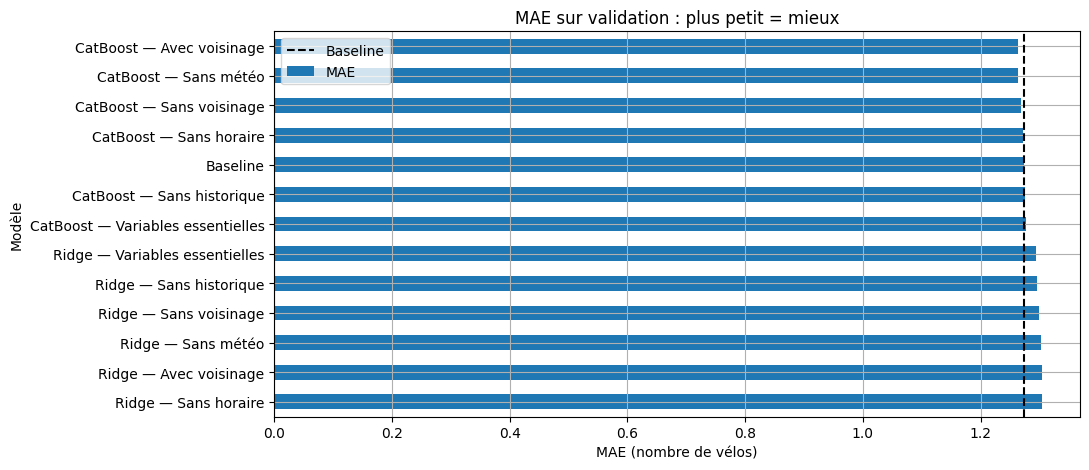

In [13]:
fig, ax = plt.subplots(figsize=(11, max(4, len(scores)*0.37)))
scores.sort_values("MAE", ascending=False).plot.barh(x="Modèle", y="MAE", ax=ax, legend=False)
ax.axvline(scores.loc[scores["Modèle"] == "Baseline", "MAE"].iloc[0],
           color="black", linestyle="--", label="Baseline")
ax.set_title("MAE sur validation : plus petit = mieux")
ax.set_xlabel("MAE (nombre de vélos)")
ax.legend()
plt.tight_layout()
plt.show()

Ici, notre témoin, c'est la **baseline** : elle prédit qu'on aura autant de vélos dans 30 minutes que maintenant. On compare Ridge et CatBoost à cette prédiction, sur les mêmes données.

CatBoost avec voisinage et CatBoost sans météo arrivent en tête, avec **1,2642 de MAE**. Avec voisinage, la RMSE est un peu meilleure : 2,1507 contre 2,1533.

La baseline est à 1,2728. L'écart est donc petit. Par contre, elle repère mieux les stations vides : **73,99 % de rappel**, contre 63,70 % pour CatBoost avec voisinage. Ridge reste derrière en MAE.

## 12. Effet des variables de voisinage

In [14]:
comparaison_voisinage = []
for famille in ("Ridge", "CatBoost"):
    sans = index_scores.loc[f"{famille} — Sans voisinage"]
    avec = index_scores.loc[f"{famille} — Avec voisinage"]
    comparaison_voisinage.append({
        "Modèle": famille,
        "MAE sans": sans["MAE"], "MAE avec": avec["MAE"],
        "Écart MAE (avec − sans)": avec["MAE"] - sans["MAE"],
        "RMSE sans": sans["RMSE"], "RMSE avec": avec["RMSE"],
        "Écart RMSE": avec["RMSE"] - sans["RMSE"],
    })
display(pd.DataFrame(comparaison_voisinage).round(4))


,Modèle,MAE sans,MAE avec,Écart MAE (avec − sans),RMSE sans,RMSE avec,Écart RMSE
0,Ridge,1.2995,1.3034,0.0038,2.1673,2.1633,-0.0041
1,CatBoost,1.2679,1.2642,-0.0038,2.1596,2.1507,-0.0088


notre témoin, c'est **le modèle sans voisinage** : on garde les variables de base, l'historique et la météo. Ce qu'on change, c'est qu'on ajoute les **3 variables de voisinage à 500 m** : le nombre de voisins, leur disponibilité moyenne et le nombre de voisins observés. On fait la même comparaison pour Ridge et CatBoost.

Pour Ridge, la MAE passe de **1,2995 à 1,3034** : ça ne l'aide pas. Pour CatBoost, elle baisse de **1,2679 à 1,2642**, et la RMSE de 2,1596 à 2,1507. Le voisinage aide un peu CatBoost, mais ça reste léger.

## 13. Étude d'ablation

Écart de MAE entre chaque variante et la configuration complète du même modèle (`Avec voisinage`). Un écart négatif indique une amélioration de la MAE après retrait des variables.

In [15]:
if EXPERIENCES_COMPLEMENTAIRES:
    rows_ablation = []
    for famille in ("Ridge", "CatBoost"):
        ref = index_scores.loc[f"{famille} — Avec voisinage"]
        for variante in ("Sans météo", "Sans historique", "Sans horaire", "Variables essentielles"):
            if variante not in EXPERIENCES:
                continue
            courant = index_scores.loc[f"{famille} — {variante}"]
            rows_ablation.append({
                "Modèle": famille, "Version": variante,
                "MAE": courant["MAE"], "RMSE": courant["RMSE"],
                "Écart MAE vs version complète": courant["MAE"] - ref["MAE"],
            })
    ablations = pd.DataFrame(rows_ablation)
    display(ablations.round(4))
else:
    print("Ablations non exécutées. Passer EXPERIENCES_COMPLEMENTAIRES à True et relancer les entraînements.")

,Modèle,Version,MAE,RMSE,Écart MAE vs version complète
0,Ridge,Sans météo,1.3032,2.1631,-0.0001
1,Ridge,Sans historique,1.2964,2.1766,-0.0069
2,Ridge,Sans horaire,1.3035,2.1631,0.0002
3,Ridge,Variables essentielles,1.2939,2.1794,-0.0095
4,CatBoost,Sans météo,1.2642,2.1533,0.0001
5,CatBoost,Sans historique,1.2750,2.1772,0.0108
6,CatBoost,Sans horaire,1.2720,2.1672,0.0078
7,CatBoost,Variables essentielles,1.2770,2.1779,0.0128


Ici, le témoin, c'est **la version complète « Avec voisinage »** : variables de base, historique, météo et voisinage. Ce qu'on change : on enlève soit la météo, soit l'historique, soit les horaires. La version « Variables essentielles » garde juste les variables de base.

Pour CatBoost, sans météo, la MAE reste à **1,2642**, quasiment comme le témoin. Sans historique, elle monte à **1,2750** ; sans horaire, à **1,2720**. Donc l'historique et les horaires nous aident.

Pour Ridge, c'est la version **« Variables essentielles »** qui marche le mieux : 1,2939 de MAE, contre 1,3034 pour le témoin.

## 14. Analyse de la baseline

Distribution des variations réelles de stock sur 30 minutes et comparaison des modèles à la baseline de persistance. Les variations observées sont utilisées uniquement pour l'analyse des résultats.

Sur validation, 39.5% des observations ne changent pas en 30 minutes.
Et 70.1% varient d'au plus 1 vélo.


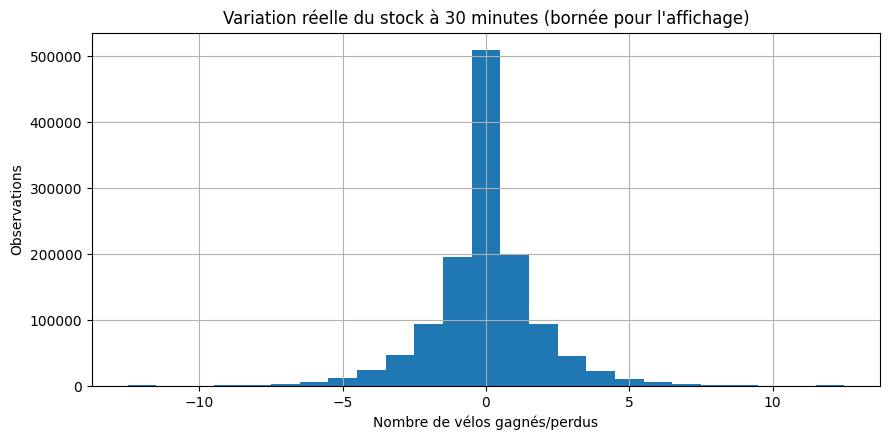

In [16]:
delta_reel = valid["available_t30"].to_numpy(dtype=float) - valid["available"].to_numpy(dtype=float)
part_stable = np.mean(delta_reel == 0)
part_petit = np.mean(np.abs(delta_reel) <= 1)
print(f"Sur validation, {part_stable:.1%} des observations ne changent pas en 30 minutes.")
print(f"Et {part_petit:.1%} varient d'au plus 1 vélo.")
fig, ax = plt.subplots()
ax.hist(np.clip(delta_reel, -12, 12), bins=np.arange(-12.5, 13.5, 1))
ax.set(title="Variation réelle du stock à 30 minutes (bornée pour l'affichage)",
       xlabel="Nombre de vélos gagnés/perdus", ylabel="Observations")
plt.tight_layout(); plt.show()

In [17]:
baseline_mae = float(index_scores.loc["Baseline", "MAE"])
for famille in ("Ridge", "CatBoost"):
    for version in ("Sans voisinage", "Avec voisinage"):
        nom = f"{famille} — {version}"
        ecart = float(index_scores.loc[nom, "MAE"] - baseline_mae)
        if ecart < -0.001:
            print(f"{nom} bat la baseline de {-ecart:.4f} vélo de MAE.")
        elif ecart > 0.001:
            print(f"{nom} reste derrière la baseline de {ecart:.4f} vélo de MAE.")
        else:
            print(f"{nom} est presque à égalité avec la baseline (écart {ecart:+.4f}).")


Ridge — Sans voisinage reste derrière la baseline de 0.0267 vélo de MAE.
Ridge — Avec voisinage reste derrière la baseline de 0.0305 vélo de MAE.
CatBoost — Sans voisinage bat la baseline de 0.0049 vélo de MAE.
CatBoost — Avec voisinage bat la baseline de 0.0087 vélo de MAE.


Ici, notre témoin, c'est toujours **la baseline**. On regarde si Ridge et CatBoost font mieux qu'elle en MAE.

**39,5 %** des observations ne changent pas en 30 minutes, et **70,1 %** changent d'au plus un vélo. Ça explique pourquoi la baseline est déjà difficile à battre. CatBoost avec voisinage gagne seulement **0,0087 vélo de MAE** sur elle.

## 15. Analyse par situation

Évaluation selon les jours, les heures de pointe, la pluie, l'amplitude des variations réelles et l'état vide/non vide des stations. Les sous-groupes peuvent se recouper. Les variations futures servent uniquement à l'analyse rétrospective.

In [18]:
# On compare une seule version de chaque modèle sur les mêmes sous-groupes.
nom_ridge = min((f"Ridge — {v}" for v in EXPERIENCES),
                key=lambda n: float(index_scores.loc[n, "MAE"]))
nom_cat = min((f"CatBoost — {v}" for v in EXPERIENCES),
              key=lambda n: float(index_scores.loc[n, "MAE"]))
MODELES_DIAG = ["Baseline", nom_ridge, nom_cat]
print("Modèles affichés :", MODELES_DIAG)

conditions = {
    "Semaine": valid["horodatage"].dt.tz_convert("Europe/Paris").dt.dayofweek.lt(5).to_numpy(),
    "Week-end": valid["horodatage"].dt.tz_convert("Europe/Paris").dt.dayofweek.ge(5).to_numpy(),
    "Heures de pointe (7–9, 17–19)": valid["heure"].isin([7,8,9,17,18,19]).to_numpy(),
    "Autres heures": ~valid["heure"].isin([7,8,9,17,18,19]).to_numpy(),
    "Variation réelle ≤ 1 vélo": (np.abs(delta_reel) <= 1),
    "Variation réelle ≥ 4 vélos": (np.abs(delta_reel) >= 4),
    "Station vide à t+30": valid["available_t30"].eq(0).to_numpy(),
    "Station non vide à t+30": valid["available_t30"].gt(0).to_numpy(),
}
if "rain" in valid.columns:
    conditions["Pluie mesurée (> 0)"] = valid["rain"].gt(0).fillna(False).to_numpy()
    conditions["Pas de pluie mesurée (= 0)"] = valid["rain"].eq(0).fillna(False).to_numpy()
elif "precipitation" in valid.columns:
    conditions["Précipitations (> 0)"] = valid["precipitation"].gt(0).fillna(False).to_numpy()
    conditions["Sans précipitations (= 0)"] = valid["precipitation"].eq(0).fillna(False).to_numpy()

lignes_sous_groupes = []
for situation, masque in conditions.items():
    if masque.sum() < 30:
        continue
    partie = valid.loc[masque]
    for nom in MODELES_DIAG:
        p = np.asarray(predictions_valid[nom])[masque]
        lignes_sous_groupes.append({"Situation": situation, "Modèle": nom,
                                    "Observations": len(partie),
                                    **mesures(partie["available_t30"], p, partie["capacity"])})
par_situation = pd.DataFrame(lignes_sous_groupes)
display(par_situation[["Situation", "Modèle", "Observations", "MAE", "RMSE", "Recall"]].round(3))

Modèles affichés : ['Baseline', 'Ridge — Variables essentielles', 'CatBoost — Avec voisinage']


,Situation,Modèle,Observations,MAE,RMSE,Recall
0,Semaine,Baseline,623295,1.276,2.215,0.669
1,Semaine,Ridge — Variables essentielles,623295,1.295,2.217,0.632
2,Semaine,CatBoost — Avec voisinage,623295,1.258,2.172,0.525
3,Week-end,Baseline,667035,1.270,2.141,0.795
4,Week-end,Ridge — Variables essentielles,667035,1.293,2.144,0.700
5,Week-end,CatBoost — Avec voisinage,667035,1.270,2.130,0.724
6,"Heures de pointe (7–9, 17–19)",Baseline,335340,1.634,2.573,0.693
7,"Heures de pointe (7–9, 17–19)",Ridge — Variables essentielles,335340,1.644,2.567,0.632
8,"Heures de pointe (7–9, 17–19)",CatBoost — Avec voisinage,335340,1.604,2.508,0.568
9,Autres heures,Baseline,954990,1.146,2.020,0.757


Ici, on garde la **baseline comme témoin** et on la compare aux meilleurs Ridge et CatBoost sur les mêmes situations. Ce qui change, c'est le groupe qu'on regarde : heures de pointe, week-end, petites ou grosses variations, stations vides, etc.

CatBoost fait mieux aux heures de pointe (**1,604 contre 1,634** de MAE) et quand le stock change d'au moins 4 vélos (**5,435 contre 5,553**).

La baseline fait mieux quand le stock change peu (**0,448 contre 0,463**) et sur les stations réellement vides (**0,505 contre 0,604**). Le week-end, c'est quasiment pareil : 1,270 de MAE pour les deux.

## 16. Comparaison des erreurs par situation

Comparaison de la MAE de la baseline et de la meilleure configuration CatBoost retenue sur validation, pour chaque sous-groupe.

Modèle,Baseline,CatBoost — Avec voisinage,Écart CatBoost − baseline
Situation,,,
Autres heures,1.146,1.145,-0.001
"Heures de pointe (7–9, 17–19)",1.634,1.604,-0.030
Semaine,1.276,1.258,-0.018
Station non vide à t+30,1.332,1.315,-0.017
Station vide à t+30,0.505,0.604,0.098
Variation réelle ≤ 1 vélo,0.448,0.463,0.015
Variation réelle ≥ 4 vélos,5.553,5.435,-0.118
Week-end,1.270,1.270,-0.000


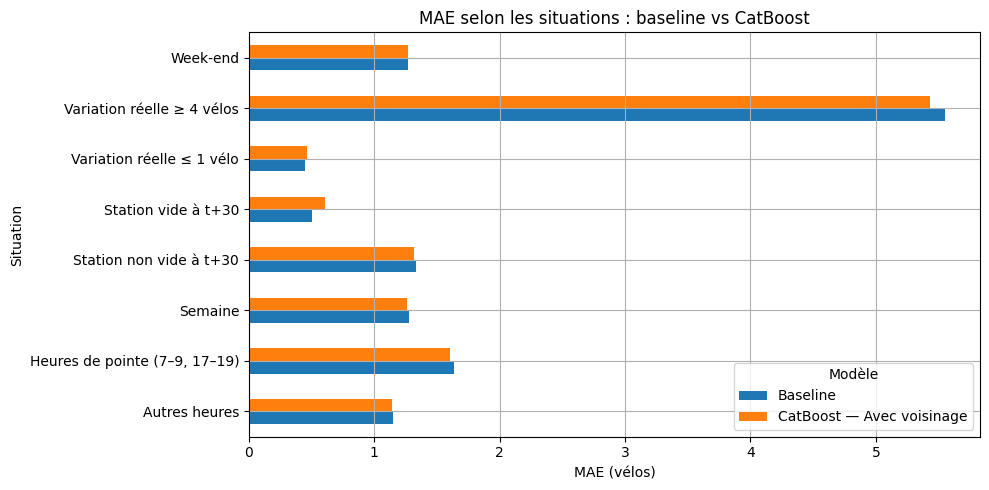

Autres heures : résultats proches (écart CatBoost − baseline : -0.001 vélo).
Heures de pointe (7–9, 17–19) : CatBoost meilleur (écart CatBoost − baseline : -0.030 vélo).
Semaine : résultats proches (écart CatBoost − baseline : -0.018 vélo).
Station non vide à t+30 : résultats proches (écart CatBoost − baseline : -0.017 vélo).
Station vide à t+30 : baseline meilleure (écart CatBoost − baseline : +0.098 vélo).
Variation réelle ≤ 1 vélo : résultats proches (écart CatBoost − baseline : +0.015 vélo).
Variation réelle ≥ 4 vélos : CatBoost meilleur (écart CatBoost − baseline : -0.118 vélo).
Week-end : résultats proches (écart CatBoost − baseline : -0.000 vélo).


In [19]:
pivot = par_situation.pivot(index="Situation", columns="Modèle", values="MAE")
pivot["Écart CatBoost − baseline"] = pivot[nom_cat] - pivot["Baseline"]
display(pivot[["Baseline", nom_cat, "Écart CatBoost − baseline"]].round(3))
ax = pivot[["Baseline", nom_cat]].plot.barh(figsize=(10, max(5, len(pivot)*0.5)))
ax.set(title="MAE selon les situations : baseline vs CatBoost", xlabel="MAE (vélos)")
plt.tight_layout(); plt.show()
for situation, r in pivot.iterrows():
    d = r["Écart CatBoost − baseline"]
    if abs(d) < 0.02:
        texte = "résultats proches"
    else:
        texte = "CatBoost meilleur" if d < 0 else "baseline meilleure"
    print(f"{situation} : {texte} (écart CatBoost − baseline : {d:+.3f} vélo).")

On garde la **baseline comme témoin** et on compare sa MAE à celle de CatBoost avec voisinage, situation par situation.

Le plus gros gain de CatBoost est sur les variations d'au moins 4 vélos (**−0,118 de MAE**). À l'inverse, la baseline reste meilleure sur les stations vides (**+0,098 de MAE pour CatBoost**).

## 17. Performances quotidiennes

Évolution des métriques par jour de validation. Cette analyse décrit la variabilité temporelle des performances sur la période déjà utilisée pour la sélection.

,Date,Modèle,Observations,MAE,RMSE
0,2026-10-30,Baseline,338985,1.343,2.237
1,2026-10-30,Ridge — Variables essentielles,338985,1.355,2.236
2,2026-10-30,CatBoost — Avec voisinage,338985,1.328,2.205
3,2026-10-31,Baseline,349920,1.343,2.310
4,2026-10-31,Ridge — Variables essentielles,349920,1.366,2.313
5,2026-10-31,CatBoost — Avec voisinage,349920,1.341,2.297
6,2026-11-01,Baseline,317115,1.189,1.938
7,2026-11-01,Ridge — Variables essentielles,317115,1.212,1.941
8,2026-11-01,CatBoost — Avec voisinage,317115,1.191,1.931
9,2026-11-02,Baseline,284310,1.197,2.188


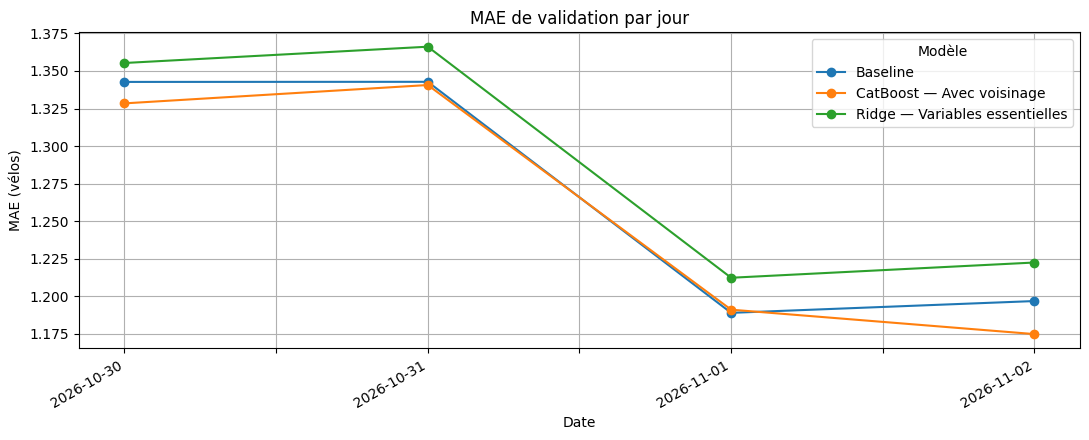

Ces courbes montrent des différences entre jours.


In [20]:
jours_validation = []
for date, indices in valid.groupby("date_paris").indices.items():
    ids = np.asarray(indices)
    bloc = valid.iloc[ids]
    for nom in MODELES_DIAG:
        p = np.asarray(predictions_valid[nom])[ids]
        jours_validation.append({"Date": date, "Modèle": nom,
                                "Observations": len(bloc),
                                **mesures(bloc["available_t30"], p, bloc["capacity"])})
par_jour = pd.DataFrame(jours_validation)
display(par_jour[["Date", "Modèle", "Observations", "MAE", "RMSE"]].round(3))
fig, ax = plt.subplots(figsize=(11, 4.5))
par_jour.pivot(index="Date", columns="Modèle", values="MAE").plot(ax=ax, marker="o")
ax.set(title="MAE de validation par jour", ylabel="MAE (vélos)", xlabel="Date")
plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.show()
print("Ces courbes montrent des différences entre jours.")

Ici, on garde la **baseline comme témoin** et on regarde les mêmes modèles jour par jour, sans changer leurs réglages.

CatBoost fait mieux les **30 et 31 octobre**, et le **2 novembre**. Le **1er novembre**, la baseline est juste devant en MAE (1,189 contre 1,191). Les écarts restent faibles.

## 18. Erreurs importantes et détection des stations vides

Examen des observations présentant les plus fortes erreurs absolues et des matrices de confusion pour la détection des stations vides à +30 minutes.

Exemples des plus grosses erreurs CatBoost :


,horodatage,station_code,available,available_t30,capacity,is_weekend,heure,pred_catboost,pred_baseline,erreur_catboost,erreur_baseline
184559,2026-10-30 11:55:00+00:00,7010,55,0,65,False,12,53,55,53,55
183344,2026-10-30 11:50:00+00:00,7010,54,0,65,False,12,52,54,52,54
182129,2026-10-30 11:45:00+00:00,7010,54,2,65,False,12,52,54,50,52
609162,2026-10-31 17:30:00+00:00,16036,53,2,60,True,18,52,53,50,51
212503,2026-10-30 14:15:00+00:00,7009,50,0,76,False,15,49,50,49,50
607947,2026-10-31 17:25:00+00:00,16036,54,6,60,True,18,53,54,47,48
211288,2026-10-30 14:10:00+00:00,7009,51,4,76,False,15,50,51,46,47
934782,2026-11-01 18:05:00+00:00,16036,55,10,60,True,19,55,55,45,45
555399,2026-10-31 13:50:00+00:00,12017,5,49,53,True,14,5,5,44,44
554184,2026-10-31 13:45:00+00:00,12017,7,50,53,True,14,7,7,43,43


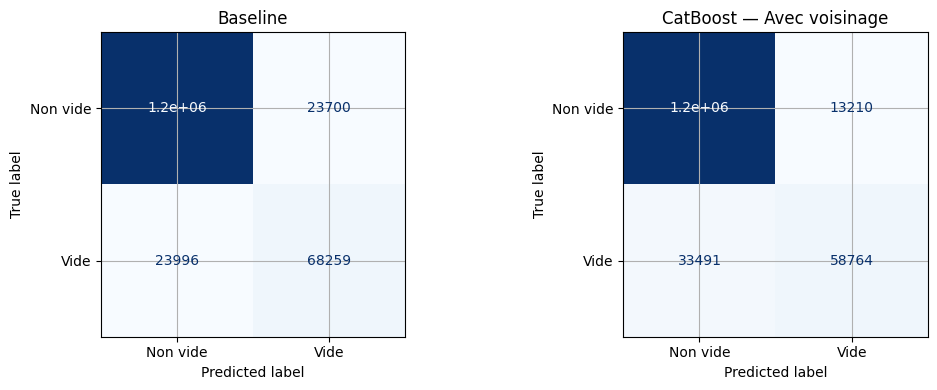

Ici, 'vide' est la classe positive : les lignes représentent la réalité et les colonnes la prédiction.


In [21]:
p_cat = pred_entiere(predictions_valid[nom_cat], valid["capacity"])
p_base = pred_entiere(predictions_valid["Baseline"], valid["capacity"])
exemples = valid[["horodatage", "station_code", "available", "available_t30",
                  "capacity", "is_weekend", "heure"]].copy()
exemples["pred_catboost"] = p_cat
exemples["pred_baseline"] = p_base
exemples["erreur_catboost"] = np.abs(exemples["available_t30"] - p_cat)
exemples["erreur_baseline"] = np.abs(exemples["available_t30"] - p_base)
print("Exemples des plus grosses erreurs CatBoost :")
display(exemples.nlargest(10, "erreur_catboost"))

reel_vide = valid["available_t30"].to_numpy() == 0
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, nom in zip(axes, ["Baseline", nom_cat]):
    p = pred_entiere(predictions_valid[nom], valid["capacity"])
    cm = confusion_matrix(reel_vide.astype(int), (p == 0).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Non vide", "Vide"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nom)
plt.tight_layout(); plt.show()
print("Ici, 'vide' est la classe positive : les lignes représentent la réalité et les colonnes la prédiction.")

Ici aussi, notre témoin, c'est **la baseline**. On regarde ce qui change quand on utilise CatBoost pour dire si une station sera vide dans 30 minutes.

CatBoost fait moins de fausses alertes de station vide : **13 210 contre 23 700**. Par contre, il rate plus de stations vraiment vides : **33 491 contre 23 996**.

Donc la baseline garde le meilleur rappel des stations vides : **73,99 % contre 63,70 %**.

## 19. Importance des variables

Importance des variables calculée par CatBoost pour la configuration avec voisinage. Les scores d'importance sont descriptifs et ne constituent pas une mesure de causalité.

,Importance relative
available,96.80
velo_meca,1.43
voisins_dispo_moyenne,0.58
heure,0.41
velo_elec,0.30
delta_t30,0.25
heure_cos,0.09
heure_sin,0.06
available_last_30,0.05
temperature_2m,0.01


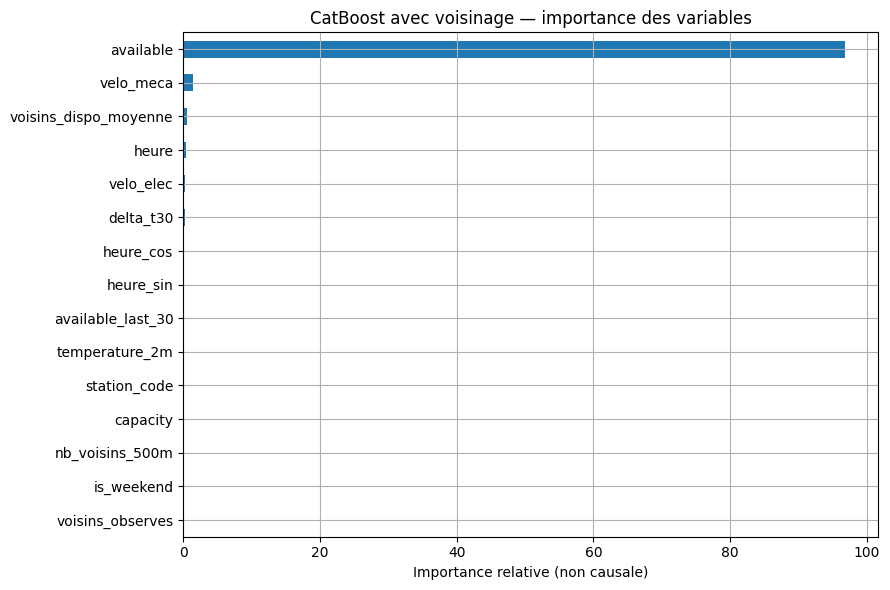

In [22]:
modele_interpret = modeles_catboost["Avec voisinage"]["modele"]
colonnes_interpret = modeles_catboost["Avec voisinage"]["features"] + ["station_code"]
importance = pd.Series(modele_interpret.feature_importances_, index=colonnes_interpret)
importance = importance.sort_values(ascending=False)
display(importance.head(15).rename("Importance relative").to_frame().round(2))
importance.head(15).sort_values().plot.barh(figsize=(9, 6),
    title="CatBoost avec voisinage — importance des variables")
plt.xlabel("Importance relative (non causale)")
plt.tight_layout(); plt.show()

## 20. Évaluation walk-forward (facultative)

On réentraîne et teste le modèle sur plusieurs périodes successives, en avançant dans le temps, pour vérifier si ses performances restent stables.

In [25]:
if not RUN_WALK_FORWARD:
    print("Walk-forward pas lancé. Mets RUN_WALK_FORWARD = True pour tester.")
else:
    pretest = df.loc[df["horodatage"] + HORIZON < DEBUT_TEST].copy()
    jours_pretest = pd.Index(sorted(pretest["date_paris"].unique()))
    # Jusqu'à 3 folds de 2 jours, après au moins 5 jours d'apprentissage.
    debut_indices = list(range(5, len(jours_pretest) - 1, 2))[-3:]
    lignes_wf = []
    for fold, pos in enumerate(debut_indices, start=1):
        debut = pd.Timestamp(jours_pretest[pos], tz="Europe/Paris").tz_convert("UTC")
        fin = pd.Timestamp(jours_pretest[min(pos + 2, len(jours_pretest)-1)],
                           tz="Europe/Paris").tz_convert("UTC") if pos + 2 < len(jours_pretest) else DEBUT_TEST
        tr = pretest.loc[pretest["horodatage"] + HORIZON < debut].copy()
        va = pretest.loc[(pretest["horodatage"] >= debut) &
                         (pretest["horodatage"] + HORIZON < fin)].copy()
        tr = sous_echantillon(tr, MAX_TRAIN_ROWS)
        va = sous_echantillon(va, MAX_VALID_ROWS)
        if tr.empty or va.empty:
            continue
        lignes_wf.append({"Fold": fold, "Période": f"{jours_pretest[pos]} à {jours_pretest[min(pos+1, len(jours_pretest)-1)]}",
                          "Modèle": "Baseline", **mesures(va["available_t30"], va["available"], va["capacity"])})
        for nom, variables in [("Ridge sans voisinage", EXPERIENCES["Sans voisinage"]),
                               ("Ridge avec voisinage", EXPERIENCES["Avec voisinage"])]:
            # Alpha fixe pour éviter de réutiliser les folds comme validation interne.
            r, p, _ = entrainer_ridge(tr, va, variables, alphas=(10.0,))
            lignes_wf.append({"Fold": fold, "Période": str(jours_pretest[pos]),
                              "Modèle": nom, **mesures(va["available_t30"], p, va["capacity"])})
        for nom, variables in [("CatBoost sans voisinage", EXPERIENCES["Sans voisinage"]),
                               ("CatBoost avec voisinage", EXPERIENCES["Avec voisinage"])]:
            c, p, _ = entrainer_catboost(tr, va, variables)
            lignes_wf.append({"Fold": fold, "Période": str(jours_pretest[pos]),
                              "Modèle": nom, **mesures(va["available_t30"], p, va["capacity"])})
        print(f"Fold {fold} fini : train={len(tr):,}, validation={len(va):,}")
    if lignes_wf:
        tableau_wf = pd.DataFrame(lignes_wf)
        display(tableau_wf[["Fold", "Modèle", "MAE", "RMSE", "Recall"]].round(3))
        display(tableau_wf.groupby("Modèle")[["MAE", "RMSE", "Recall"]].agg(["mean", "std"]).round(3))
    else:
        print("Pas assez de jours pour faire les folds prévus.")

Walk-forward pas lancé. Mets RUN_WALK_FORWARD = True pour tester.


On n'a pas lancé le walk-forward pour l'instant, donc pas de résultats à commenter.

## 21. Évaluation sur le test réservé

Après fixation des familles de variables et des hyperparamètres sur validation, réentraînement sur l'ensemble entraînement + validation, puis évaluation sur le test réservé.


In [24]:
if not RUN_FINAL_TEST:
    print("Test final pas lancé pour le moment.")
    print("Modèles retenus sur la validation :", nom_ridge, "et", nom_cat)
else:
    # Les hyperparamètres et familles de variables sont fixés AVANT l'ouverture du test.
    tr_final = pd.concat([train_complet, valid_complet], ignore_index=True)
    tr_final = sous_echantillon(tr_final, MAX_TRAIN_ROWS)
    final_scores = [tableau_mesures("Baseline", test_reserve, test_reserve["available"].to_numpy())]

    var_r = modeles_ridge[nom_ridge.replace("Ridge — ", "")]["features"]
    alpha_r = modeles_ridge[nom_ridge.replace("Ridge — ", "")]["params"]["alpha"]
    # Réentraînement sans consulter le test pour choisir alpha.
    prepa = ColumnTransformer([
        ("num", Pipeline([
            ("imputation", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("standardisation", StandardScaler()),
        ]), var_r),
        ("station", OneHotEncoder(handle_unknown="ignore"), ["station_code"]),
    ], sparse_threshold=0.3)
    final_r = Pipeline([("preparation", prepa),
                        ("regression", Ridge(alpha=alpha_r, solver="lsqr"))])
    final_r.fit(tr_final[var_r + ["station_code"]], tr_final["available_t30"].astype(float))
    pr = final_r.predict(test_reserve[var_r + ["station_code"]])
    final_scores.append(tableau_mesures(nom_ridge, test_reserve, pr))

    cle_cat = nom_cat.replace("CatBoost — ", "")
    var_c = modeles_catboost[cle_cat]["features"]
    iters_c = modeles_catboost[cle_cat]["params"]["iterations"]
    med_c = tr_final[var_c].median(numeric_only=True).fillna(0)
    xtr = preparer_catboost(tr_final, var_c, med_c)
    xte = preparer_catboost(test_reserve, var_c, med_c)
    final_c = CatBoostRegressor(
        iterations=iters_c, depth=CATBOOST_DEPTH, learning_rate=0.07,
        loss_function="MAE", random_seed=SEED,
        thread_count=CATBOOST_THREADS, verbose=False, allow_writing_files=False)
    final_c.fit(xtr, tr_final["available_t30"].astype(float), cat_features=["station_code"], verbose=False)
    pc = final_c.predict(xte)
    final_scores.append(tableau_mesures(nom_cat, test_reserve, pc))
    display(pd.DataFrame(final_scores).sort_values("MAE").round(4))
    print("Le test a été consulté")

Test final pas lancé pour le moment.
Modèles retenus sur la validation : Ridge — Variables essentielles et CatBoost — Avec voisinage
